# 6 · Recommendations: reset flight economics before pursuing growth

## Objective and exact question
**REAME.md Q6:** “What short- and long-term actions should NorthByte take, and how will they affect customers, employees and communities?”

**Case Package Q6 (printed p.17):** “What short-term and long-term actions would you recommend, and how would they affect NorthByte's customers, employees, and the communities it serves?”

This decision notebook synthesizes the **completed analyses in notebooks 01–05**. It prioritizes actions, distinguishes observed financial exposure from achievable improvement, and identifies the evidence required before changing schedules, staffing, leases or customer offers. All amounts are **CAD**.

## tl;dr
1. **Review capacity and fuel/crew economics first**, starting with Montreal↔Vancouver and Toronto's links to Halifax, Montreal and Ottawa. These eight directions explain **71.2% of the CAD36.10m decline**. Their losses identify review priorities; they do not measure closure savings.
2. **Audit maintenance procurement and reliability**, then prevent avoidable disruption while honoring all valid refunds. Maintenance rose **CAD13.00m**; refund outflow rose **CAD1.14m**. Required maintenance, crew rest and safety remain constraints.
3. **Reconstruct gate contracts and review Halifax A3 / Ottawa A2**, then test optional ancillaries in direct channels. The two gates carry **CAD441,444.87 of forecast calendar-2026 exposure**, while a hypothetical 10% ancillary uplift adds only **CAD395,896.38 of receipts before costs**.
4. **Build matched itinerary economics before long-term network or Rewards redesign.** Protect regional connectivity, use employee redeployment and consultation, and expand only after incremental network contribution is demonstrated.

There is **no supported break-even forecast**. A 3% reduction in FY2025–26 fuel-plus-crew expense would mechanically improve the pre-gate proxy by **CAD4.74m**, leaving **CAD43.93m negative** before implementation costs. The rates are illustrative sensitivities, not validated targets or savings commitments. Do not add overlapping initiatives into a promised total.

## Context & methods

Use the five completed analyses as the source of truth for the case's two September–August fiscal years: **FY2024–25 = [2024-09-01, 2025-09-01)** and **FY2025–26 = [2025-09-01, 2026-09-01)**. Read their exported tables rather than estimating benefits from narrative claims. Reconcile shared annual totals across analyses and calculate every sensitivity in integer cents with explicit rates.

### Key assumptions and decision limits
- **Dates:** the user's DD/MM/YYYY assumption applies only to **7,902** originally ambiguous transaction dates. **759** outside-period transactions, net **CAD499,209.97**, are reconciled separately; all unambiguous and 57 duplicate-resolved rows retain their interpretation. This notebook inherits that scope without recleaning records.
- **Outcome:** signed purchase/refund-date receipts less flight-date fuel, crew, maintenance and food is a **pre-gate activity-period proxy**, not matched-flight or audited accrual profit. Flight counts are route/date keys with four distinct expense categories; transaction counts are not passengers, seats or load factors.
- **Cost changes:** more flights, route mix and input rates are confounded. Neither the flight-volume decomposition nor a route's loss is an avoidable-cost estimate.
- **Gate timing:** calendar-2026 lease prices are forecast, not observed. Notebook 05's FY2025–26 gate estimate uses four months of observed calendar-2025 rates plus eight months of forecast calendar-2026 rates. Every airport's full gate bill, including unassigned overhead, is allocated once across departures; arrivals add no gate charge. A lease allocation is not a cancellable cost.
- **Scenarios:** each rate is an analyst-selected stress test on a named observed base, keeping other receipts, service and costs fixed. Pilot cost, execution delays, revenue displacement and network spillovers are unknown. Report gross arithmetic headroom before these deductions; do not call it a forecast, ROI or budget.
- **Values:** the case requires safety, fair treatment and community connectivity. Preserve the case's full-fare refund promise for cancellations or delays over three hours; reduce preventable disruptions, never valid refund access.

The case narrative approximates the pre-gate loss at CAD40m and onset in February 2025. Analysis 01 measures **CAD48.67m** and first negative month **March 2025** under both tested date interpretations. Use the measured definition and retain the discrepancy.

## Evidence provenance

All source artifacts below are completed analyses of the supplied case data. The five notebooks contain their source-data methods, assumptions and checks. Source paths and SHA-256 fingerprints of every imported CSV are exported in `06_provenance.csv`; no external research or interim text report is a runtime dependency.

| Completed analysis | Evidence used in this notebook | Decision supported |
|---|---|---|
| [01 Financial trends](01_financial_trends.ipynb) | `01_annual_financials.csv`, `01_operating_activity.csv`, `01_expense_category_change.csv`, `01_date_scope_reconciliation.csv` | Size of loss, schedule growth, maintenance exposure and date scope |
| [02 Network profitability](02_network_profitability.ipynb) | `02_directional_route_profitability.csv`, `02_directional_route_changes.csv`, `02_two_way_corridors.csv`, `02_cross_subsidy_pools.csv` | Corridor review order and protection of positive contributions |
| [03 Loss drivers](03_loss_drivers.ipynb) | `03_annual_exact_totals.csv`, `03_decline_bridge.csv`, `03_cost_volume_and_average.csv`, `03_rewards_payment.csv` | Exact cost/receipt bridge, volume versus average mix, Rewards uncertainty |
| [04 Revenue composition](04_revenue_analysis.ipynb) | `04_revenue_bridge.csv`, `04_booking_channel.csv`, `04_connecting_booking_proxy.csv`, `04_growth_sensitivities.csv` | Refund and optional ancillary tests, direct-channel scope, connection caveat |
| [05 Gate leases](05_gate_costs.ipynb) | `05_gate_change_forecast.csv`, `05_forecast_scenarios.csv`, `05_fiscal_allocation_summary.csv`, `05_unassigned_gate_leases.csv` | Contract reconstruction, annual unassigned exposure and fiscal fixed overhead |

All CSV paths are under `outputs/tables/`. Business constraints come from **FirstByte 2026 Case Package.pdf**, printed pp.8–10 (situation, customers, costs), pp.12–14 (network, gates, values), and p.17 (question). `REAME.md` states the deliverable question.

In [1]:
from pathlib import Path
from decimal import Decimal, ROUND_HALF_UP
from fractions import Fraction
import csv
import hashlib
import sys

import nbformat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd() if (Path.cwd() / 'src/analysis_common.py').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
from analysis_common import FY_ORDER, COLORS, setup_style, save_figure, save_table

setup_style()
pd.set_option('display.max_colwidth', 90)
TABLES = ROOT / 'outputs/tables'
checks = []
provenance_rows = []


def check(name, condition, detail):
    assert bool(condition), f'{name}: {detail}'
    checks.append({'check': name, 'passed': True, 'detail': str(detail)})


def read_table(stem):
    path = TABLES / f'{stem}.csv'
    frame = pd.read_csv(path)
    provenance_rows.append({
        'source': str(path.relative_to(ROOT)),
        'rows': len(frame),
        'sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
        'role': 'Completed analysis input table',
    })
    return frame


def as_cents(value):
    return int((Decimal(str(value)) * 100).quantize(Decimal('1'), rounding=ROUND_HALF_UP))


def rate_cents(base_cents, rate):
    return int((Decimal(int(base_cents)) * Decimal(str(rate))).quantize(Decimal('1'), rounding=ROUND_HALF_UP))


def money(cents):
    return f'CAD {int(cents) / 100:,.2f}'


def millions(cents):
    return f'CAD {int(cents) / 100_000_000:,.2f}m'


def show_money_table(frame, columns):
    display(frame.style.format({col: '{:,.2f}' for col in columns}).hide(axis='index'))


annual = read_table('03_annual_exact_totals').set_index('fiscal_year').reindex(FY_ORDER)
trend = read_table('01_annual_financials').set_index('Fiscal year').reindex(FY_ORDER)
activity = read_table('01_operating_activity').set_index('Fiscal year').reindex(FY_ORDER)
cost_categories = read_table('01_expense_category_change').set_index('cost_type')
scope = read_table('01_date_scope_reconciliation')
routes = read_table('02_directional_route_profitability')
route_changes = read_table('02_directional_route_changes')
corridors = read_table('02_two_way_corridors')
pools = read_table('02_cross_subsidy_pools').set_index('fiscal_year')
bridge = read_table('03_decline_bridge')
cost_volume = read_table('03_cost_volume_and_average').set_index('cost_type')
rewards_payment = read_table('03_rewards_payment')
receipts = read_table('04_revenue_bridge').set_index('fiscal_year').reindex(FY_ORDER)
channels = read_table('04_booking_channel')
connections = read_table('04_connecting_booking_proxy')
receipt_sensitivities = read_table('04_growth_sensitivities')
gate_forecast = read_table('05_gate_change_forecast')
gate_scenarios = read_table('05_forecast_scenarios')
gate_fiscal = read_table('05_fiscal_allocation_summary').set_index('fiscal_year')
unassigned_gates = read_table('05_unassigned_gate_leases')

# Inspect completed notebook methods and verify saved execution state.
source_notebooks = [
    '01_financial_trends', '02_network_profitability', '03_loss_drivers',
    '04_revenue_analysis', '05_gate_costs',
]
for stem in source_notebooks:
    path = ROOT / 'notebooks' / f'{stem}.ipynb'
    source_nb = nbformat.read(path, as_version=4)
    code_cells = [cell for cell in source_nb.cells if cell.cell_type == 'code']
    check(stem + ' saved execution', all(cell.execution_count is not None for cell in code_cells), len(code_cells))
    check(stem + ' no saved errors', not any(
        output.output_type == 'error' for cell in code_cells for output in cell.outputs
    ), 'Saved outputs checked; upstream not rerun by Q6')
    provenance_rows.append({
        'source': str(path.relative_to(ROOT)),
        'rows': len(source_nb.cells),
        'sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
        'role': 'Completed source notebook methods and narrative',
    })

save_table(pd.DataFrame(provenance_rows), '06_provenance')
print(f'Loaded {len(provenance_rows) - 5} completed CSVs and inspected five executed source notebooks.')

Loaded 20 completed CSVs and inspected five executed source notebooks.


## Data checks and financial context

Reconcile the shared annual bases across Questions 1, 2, 3 and 4 before sizing actions. Question 5 adds a separate, explicitly estimated fixed-overhead layer. None of the proposed actions changes the date scope or pretends that purchase-date receipts can identify the margin of a particular flight.

In [2]:
old, new = annual.iloc[0], annual.iloc[1]
loss_cents = -int(new.contribution_proxy_cents)
decline_cents = int(old.contribution_proxy_cents - new.contribution_proxy_cents)

for fy in FY_ORDER:
    check(fy + ' Q1/Q3 net revenue', as_cents(trend.loc[fy, 'Net transaction revenue']) == int(annual.loc[fy, 'net_revenue_cents']), 'Exact cents')
    check(fy + ' Q1/Q3 flight costs', as_cents(trend.loc[fy, 'Recorded flight expenses']) == int(annual.loc[fy, 'flight_cost_cents']), 'Exact cents')
    check(fy + ' Q2/Q3 contribution', as_cents(pools.loc[fy, 'net_contribution_cad']) == int(annual.loc[fy, 'contribution_proxy_cents']), 'Exact cents')
    check(fy + ' Q3/Q4 net receipts', int(receipts.loc[fy, 'net_cents']) == int(annual.loc[fy, 'net_revenue_cents']), 'Exact cents')

check('Adverse/positive bridge sums to decline', int(bridge.change_in_proxy_cents.sum()) == -decline_cents, decline_cents)
excluded = scope[~scope.in_scope.astype(str).str.lower().eq('true')]
check('Inherited date exclusion', int(excluded.rows.sum()) == 759 and as_cents(excluded['Net transaction amount (CAD)'].sum()) == 49_920_997, '759 rows; CAD499,209.97')
check('Date status reconciliation', int(scope.rows.sum()) == 558_129 and int(scope.loc[scope.date_status.eq('assumed_day_first'), 'rows'].sum()) == 7_902, 'Full source population')

fuel_crew_cents = int(cost_volume.loc[['Fuel', 'Crew'], 'fy26_cost_cents'].sum())
maintenance_cents = int(cost_volume.loc['Maintenance', 'fy26_cost_cents'])
refund_cents = int(receipts.loc[FY_ORDER[1], 'refund_cents'])
ancillary_cents = int(receipts.loc[FY_ORDER[1], 'ancillary_cents'])
fy_gate_cents = int(gate_fiscal.loc[FY_ORDER[1], 'estimated_lease_cents'])
after_gate_loss_cents = loss_cents + fy_gate_cents

flight_growth_pct = (activity.loc[FY_ORDER[1], 'Observed flights'] / activity.loc[FY_ORDER[0], 'Observed flights'] - 1) * 100
fuel_crew_refund_adverse = -int(bridge.loc[bridge.driver.isin(['Fuel', 'Crew', 'Refunds']), 'change_in_proxy_cents'].sum())
fuel_crew_volume = cost_volume.loc[['Fuel', 'Crew'], 'volume_effect_cad'].sum()
fuel_crew_growth_cents = int(cost_volume.loc[['Fuel', 'Crew'], 'growth_cents'].sum())

context = pd.DataFrame([
    ['Net transaction receipts', int(old.net_revenue_cents), int(new.net_revenue_cents), 'Observed purchase-period receipts'],
    ['Recorded flight operating expense', int(old.flight_cost_cents), int(new.flight_cost_cents), 'Observed flight-date expense'],
    ['Pre-gate activity-period proxy', int(old.contribution_proxy_cents), int(new.contribution_proxy_cents), 'Mixed-clock comparison; not accrual profit'],
    ['Estimated gate expense', int(gate_fiscal.loc[FY_ORDER[0], 'estimated_lease_cents']), fy_gate_cents, 'FY2 includes eight forecast months'],
    ['Proxy after estimated gate allocation', int(old.contribution_proxy_cents) - int(gate_fiscal.loc[FY_ORDER[0], 'estimated_lease_cents']), -after_gate_loss_cents, 'Conditional on gate forecast / accrual'],
], columns=['Metric', 'FY2024-25 cents', 'FY2025-26 cents', 'Status'])
for fy in FY_ORDER:
    context[fy + ' CAD'] = context[fy + ' cents'] / 100
context['Change CAD'] = (context['FY2025-26 cents'] - context['FY2024-25 cents']) / 100
save_table(context, '06_financial_context')
show_money_table(context[['Metric', 'FY2024-25 CAD', 'FY2025-26 CAD', 'Change CAD']], ['FY2024-25 CAD', 'FY2025-26 CAD', 'Change CAD'])

display(Markdown(
    f'**Decision context.** Flight volume rose **{flight_growth_pct:.2f}%** while net receipts rose '
    f'**{(int(new.net_revenue_cents) / int(old.net_revenue_cents) - 1) * 100:.2f}%**. '
    f'Fuel, crew and higher refunds contribute **{millions(fuel_crew_refund_adverse)} '
    f'({fuel_crew_refund_adverse / decline_cents * 100:.2f}%)** of the measured decline. '
    f'The volume component is **{fuel_crew_volume / (fuel_crew_growth_cents / 100) * 100:.2f}%** of fuel/crew growth; '
    'this index comparison is not proof of preventable cost. '
    f'Gate estimates deepen the FY2 proxy loss to **{money(after_gate_loss_cents)}**.'
))

Metric,FY2024-25 CAD,FY2025-26 CAD,Change CAD
Net transaction receipts,"180,419,443.08","189,710,371.80","9,290,928.72"
Recorded flight operating expense,"192,985,563.99","238,376,476.25","45,390,912.26"
Pre-gate activity-period proxy,"-12,566,120.91","-48,666,104.45","-36,099,983.54"
Estimated gate expense,"9,806,600.00","10,023,129.36","216,529.36"
Proxy after estimated gate allocation,"-22,372,720.91","-58,689,233.81","-36,316,512.90"


**Decision context.** Flight volume rose **20.33%** while net receipts rose **5.15%**. Fuel, crew and higher refunds contribute **CAD 32.31m (89.51%)** of the measured decline. The volume component is **82.67%** of fuel/crew growth; this index comparison is not proof of preventable cost. Gate estimates deepen the FY2 proxy loss to **CAD 58,689,233.81**.

## Results: where to act first

### Priority 1 · Test schedule and fuel/crew economics on four large problem corridors

**Short term (days 0–90):** hold discretionary net schedule expansion while finance and operations reconcile booking revenue to flown itineraries on Montreal↔Vancouver, Halifax↔Toronto, Montreal↔Toronto and Ottawa↔Toronto. Evaluate retiming, frequency consolidation and aircraft fit before any permanent withdrawal. Obtain fuel quantities/prices, crew hours/overtime and positioning, aircraft type, seats, flown demand and contract avoidability. Use fatigue-safe rostering and operational fuel procedures approved by the safety team.

**Financial justification:** these eight directions represent 71.2% of deterioration, and the fuel/crew expense base is CAD157.95m. The FY2 positive pool of CAD12.37m covers only 20.27% of CAD61.04m route losses. A 3% expense sensitivity on fuel and crew is useful for scale, but no 3% achievable reduction is demonstrated. Maintenance and lost ticket/connection revenue must enter any frequency decision; do not book the sum of route losses as savings.

**Long term (months 3–12):** compare each pilot with a matched seasonal control using incremental network contribution after genuinely avoidable cost, displaced receipts and transition expense. Protect Toronto↔Calgary and Calgary↔Vancouver's positive contributions while checking capacity and itinerary economics before redeployment. Positive historical proxies do not justify untested growth. Permanent changes require community consultation and a viable connection plan.

corridor,loss_cad,deterioration_cad,share_of_network_decline_pct
YUL ↔ YVR,"19,722,986.90","11,633,207.52",32.22
YHZ ↔ YYZ,"9,160,468.98","5,558,570.53",15.40
YUL ↔ YYZ,"8,433,879.55","4,652,398.15",12.89
YOW ↔ YYZ,"7,204,076.87","3,843,537.66",10.65


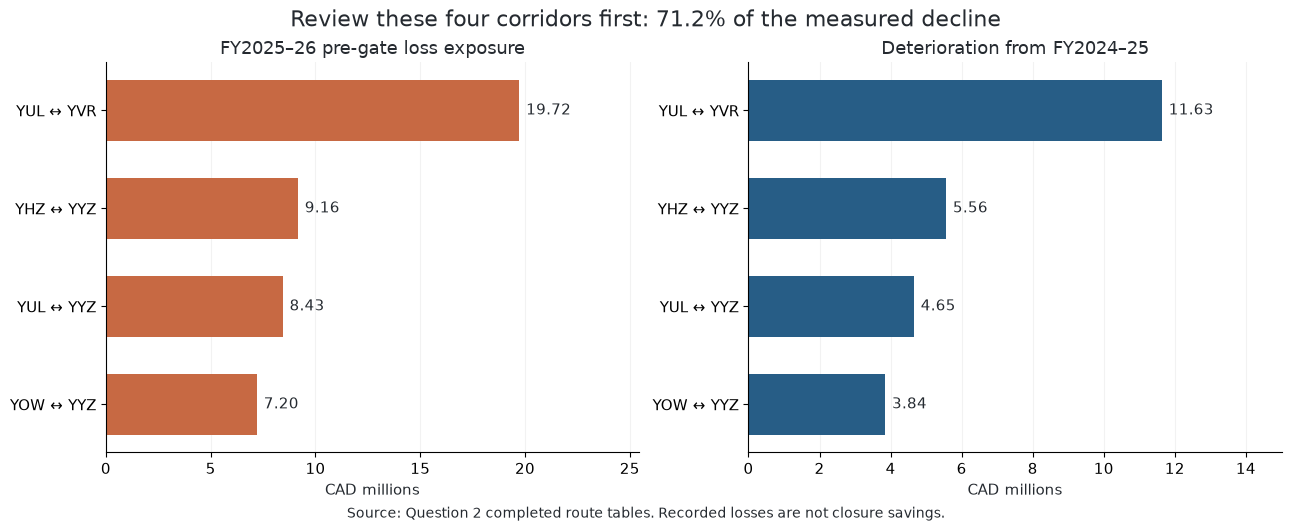

In [3]:
top_eight = route_changes.sort_values('change_cad').head(8).copy()
check('Eight directions form four reciprocal corridors', len(top_eight) == 8 and top_eight.route_id.str[:3].nunique() >= 4, 'Further corridor grouping below')
top_eight['corridor'] = top_eight.route_id.map(lambda route: ' ↔ '.join(sorted([route[:3], route[3:]])))
review_changes = top_eight.groupby('corridor').change_cad.sum().rename('change_cad')
review = corridors.loc[corridors.fiscal_year.eq(FY_ORDER[1])].merge(review_changes, on='corridor', validate='one_to_one')
review['loss_cad'] = -review.contribution_cad
review['deterioration_cad'] = -review.change_cad
review['share_of_network_decline_pct'] = review.deterioration_cad / (decline_cents / 100) * 100
review = review.sort_values('loss_cad', ascending=False)
check('Four full reciprocal corridors selected', len(review) == 4 and review.directions.eq(2).all(), list(review.corridor))
top_eight_decline_cents = sum(as_cents(value) for value in top_eight.change_cad) * -1
check('Corridor deterioration matches eight directions', sum(as_cents(value) for value in review.deterioration_cad) == top_eight_decline_cents, 'Exact cents')
review['interpretation'] = 'Observed loss exposure; avoidable savings and connection effects unknown'
save_table(review, '06_corridor_review')
show_money_table(review[['corridor', 'loss_cad', 'deterioration_cad', 'share_of_network_decline_pct']], ['loss_cad', 'deterioration_cad', 'share_of_network_decline_pct'])

fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.2), layout='constrained')
for ax, column, title, color in [
    (axes[0], 'loss_cad', 'FY2025–26 pre-gate loss exposure', COLORS['orange']),
    (axes[1], 'deterioration_cad', 'Deterioration from FY2024–25', COLORS['blue']),
]:
    values = review[column] / 1e6
    bars = ax.barh(review.corridor, values, color=color, height=.62)
    ax.invert_yaxis()
    ax.set_xlim(0, values.max() * 1.29)
    ax.set_xlabel('CAD millions')
    ax.set_title(title, fontsize=13)
    ax.grid(axis='x', alpha=.16)
    ax.set_axisbelow(True)
    ax.bar_label(bars, labels=[f'{value:.2f}' for value in values], padding=5)
fig.suptitle('Review these four corridors first: 71.2% of the measured decline', fontsize=16)
fig.supxlabel('Source: Question 2 completed route tables. Recorded losses are not closure savings.', fontsize=10)
save_figure(fig, '06_corridor_review')
plt.show()

### Priority 2 · Investigate maintenance spend while protecting aircraft reliability

**Days 0–60:** engineering and finance should validate vendor invoices, parts purchasing, planned versus unplanned work and aircraft/route mix behind the **CAD13,003,356.24 increase**, on a FY2 maintenance base of **CAD71,387,479.95**. Test purchasing terms and maintenance planning; preserve required tasks, airworthiness and staffing capability. The completed tables cannot identify waste or deferred work.

**Months 3–12:** expand only purchasing/planning changes that lower verified cost per comparable aircraft cycle without worsening safety, dispatch reliability or maintenance backlog. A **1% maintenance-cost sensitivity** is CAD713,874.80 before project cost. It is a scale marker, not permission for a blanket maintenance cut. Reliability improvements may also affect refunds and crew expense, so do not add those effects twice. Employees gain clearer planning and training; workload compression or unsafe deferrals would fail the pilot.

### Priority 3 · Prevent avoidable disruptions and refund outflow

**Days 0–90:** add cancellation/delay causes and original-ticket linkage, then test operational changes on the highest preventable disruption burden. Preserve full eligible refunds and timely processing. FY2 refunds were **CAD7,821,083.19**, up **CAD1,142,771.50**; they explain **3.17%** of the measured deterioration. Refund counts per ticket transaction are not cancellation probabilities, and weather or cause attribution cannot be inferred from these exports.

A hypothetical **10% fall in refund outflow from fewer eligible disruptions**, holding sales constant, retains **CAD782,108.32** before the prevention cost. It cannot be achieved simply by denying refunds. **Months 3–12:** fund spare coverage or resilience only when linked disruption evidence shows net benefit after staffing, fuel, maintenance and recovery expense. Customers gain more reliable trips; employees need adequate recovery resources; regional and northern travellers should retain workable alternatives when disruptions occur.

### Priority 4 · Reconstruct lease terms and test consolidation of two unassigned gates

**Days 0–30:** finance and station teams should recover missing calendar-2026 contracts. Budget **CAD10,095,844.04** on the unchanged portfolio under Question 5's gate-specific escalation scenario, then replace estimates with contracts. The earlier rates are not current quoted terms.

**Days 30–90:** verify peak occupancy, contingency use, accessibility and contract exit/sharing rights for **Halifax A3 and Ottawa A2**. Their calendar-2025 bill was **CAD433,500.00**; the calendar-2026 forecast carries **CAD441,444.87**. That is an **annual gross ceiling only if both leases can disappear without replacement**, penalties, extra handling or service damage; it is not assured savings or a FY2 expense reduction. Pursue sharing or consolidation at the next contractual opportunity after the airport confirms feasibility. A smaller bill is attractive, but missed departures, staff overload or loss of a community connection would defeat it.

### Priority 5 · Test clear optional ancillaries on direct channels

**Days 30–90:** test an opt-in baggage/seat offer with a transparent all-in price and control group, using Direct Web and Mobile App. Together they account for **62.07% of FY2 net receipts**, which justifies a large test surface, not an assumption of lower distribution cost. Measure incremental contribution after servicing, acquisition and technology cost, ticket cannibalization, complaints and conversion.

The **network-wide ancillary base is CAD3,958,963.76**, only 2.00% of gross receipts. A 10% network-wide uplift is **CAD395,896.38 before costs**. A direct-only pilot has a smaller observed ancillary base and a separately calculated sensitivity below; do not attach the whole-network amount to the direct test. **Months 3–12:** scale only net-positive offers that customers understand. Do not increase compulsory fees, obscure prices or tighten valid refunds to manufacture revenue. Train front-line staff and keep non-digital booking paths usable for communities with limited access.

### Separate financial sensitivities: scale, not promised improvement

The following calculations reuse Question 3's exact cost bases and Question 4's exact receipt bases. **1%, 3% and 5%** fuel/crew cost changes, **1%** maintenance, and **10%** ancillary/refund changes are arbitrary sensitivity parameters, not inferred performance estimates or probability bounds. Expense sensitivities assume unchanged flying, receipts and safety; a schedule pilot must instead measure its lost receipts and avoidable costs.

For each FY2 sensitivity, `gross change = observed base × selected rate`; `remaining pre-gate loss = CAD48,666,104.45 − gross change`. These are one-at-a-time comparisons. The combined ancillary/refund row reproduces Question 4's receipt calculation and must not be added to its component rows. Direct-only ancillary and network-wide ancillary are nested alternatives. Gate exposure remains on its separate calendar-2026 basis and has no FY2 residual calculation.

In [4]:
direct = channels.loc[
    channels.fiscal_year.eq(FY_ORDER[1]) & channels.booking_channel.isin(['Direct Web', 'Mobile App'])
]
direct_ancillary_cents = int(direct.ancillary_cents.sum())
direct_net_cents = int(direct.net_cents.sum())
connection_latest = connections.loc[
    connections.fiscal_year.eq(FY_ORDER[1]) & connections.booking_class.eq('Connection-compatible (inferred)')
].iloc[0]
points_latest = rewards_payment.loc[
    rewards_payment.fiscal_year.eq(FY_ORDER[1]) & rewards_payment.payment_method.eq('Points + Cash')
].iloc[0]
unassigned_forecast_cents = int(gate_forecast.loc[gate_forecast.assigned_route_count.eq(0), 'forecast_2026_cents'].sum())
check('Two specific unassigned gates', set(
    zip(gate_forecast.loc[gate_forecast.assigned_route_count.eq(0), 'departure_airport'],
        gate_forecast.loc[gate_forecast.assigned_route_count.eq(0), 'gate_number'])
) == {('YHZ', 'A3'), ('YOW', 'A2')}, 'No assumption of physical inactivity')
check('Forecast portfolio reconciliation', int(gate_forecast.forecast_2026_cents.sum()) == int(gate_scenarios.loc[gate_scenarios.scenario.str.contains('primary'), 'forecast_2026_cents'].iloc[0]), 'Gate-specific forecast')

specifications = [
    ('FC1', 'Fuel + crew: 1% expense sensitivity', fuel_crew_cents, '0.01', 'FY2025-26', '03_cost_volume_and_average.csv', 'Alternative to FC3 / FC5; overlaps schedule and reliability work'),
    ('FC3', 'Fuel + crew: 3% expense sensitivity', fuel_crew_cents, '0.03', 'FY2025-26', '03_cost_volume_and_average.csv', 'Alternative to FC1 / FC5; unchanged flying and receipts assumed'),
    ('FC5', 'Fuel + crew: 5% expense sensitivity', fuel_crew_cents, '0.05', 'FY2025-26', '03_cost_volume_and_average.csv', 'Alternative to FC1 / FC3; no achievable rate established'),
    ('M1', 'Maintenance: 1% expense sensitivity', maintenance_cents, '0.01', 'FY2025-26', '03_cost_volume_and_average.csv', 'No deferral; overlaps reliability and schedule work'),
    ('R10', 'Refunds: 10% lower outflow', refund_cents, '0.10', 'FY2025-26', '04_revenue_bridge.csv', 'Fewer disruptions; valid refunds preserved; prevention cost unknown'),
    ('A10', 'Ancillaries: 10% higher receipts, network', ancillary_cents, '0.10', 'FY2025-26', '04_revenue_bridge.csv', 'Network-wide; includes direct channels; contribution cost unknown'),
    ('D10', 'Ancillaries: 10% higher receipts, direct only', direct_ancillary_cents, '0.10', 'FY2025-26', '04_booking_channel.csv', 'Subset of A10; pilot scale before cost and cannibalization'),
    ('AR10', 'Combined 10% ancillary / refund sensitivity', ancillary_cents + refund_cents, '0.10', 'FY2025-26', '04_revenue_bridge.csv', 'Alternative to A10 + R10; reproduces Q4; before costs'),
    ('G100', 'Both unassigned gates: full annual exposure', unassigned_forecast_cents, '1.00', 'Calendar 2026 forecast', '05_gate_change_forecast.csv', 'Conditional annual ceiling; not FY2 savings; no release assumption validated'),
]
scenario_rows = []
for scenario_id, label, base, rate, period, source, limitation in specifications:
    improvement_cents = rate_cents(base, rate)
    fiscal_scenario = period == 'FY2025-26'
    scenario_rows.append({
        'scenario_id': scenario_id,
        'scenario': label,
        'period': period,
        'rate': Decimal(rate),
        'base_cents': base,
        'base_cad': base / 100,
        'gross_improvement_cents': improvement_cents,
        'gross_improvement_cad': improvement_cents / 100,
        'share_of_pre_gate_loss_pct': improvement_cents / loss_cents * 100 if fiscal_scenario else np.nan,
        'remaining_pre_gate_loss_cents': loss_cents - improvement_cents if fiscal_scenario else pd.NA,
        'remaining_pre_gate_loss_cad': (loss_cents - improvement_cents) / 100 if fiscal_scenario else np.nan,
        'source_table': source,
        'limitation': limitation,
    })
scenarios = pd.DataFrame(scenario_rows)
scenarios['remaining_pre_gate_loss_cents'] = scenarios.remaining_pre_gate_loss_cents.astype('Int64')
by_id = scenarios.set_index('scenario_id')
save_table(scenarios, '06_financial_sensitivities')
show_money_table(
    scenarios[['scenario_id', 'scenario', 'base_cad', 'gross_improvement_cad', 'remaining_pre_gate_loss_cad']],
    ['base_cad', 'gross_improvement_cad', 'remaining_pre_gate_loss_cad']
)

display(Markdown(
    f'The direct-only ancillary base is **{money(direct_ancillary_cents)}**, so a 10% receipt sensitivity is '
    f'**{money(by_id.loc["D10", "gross_improvement_cents"])}**, versus '
    f'**{money(by_id.loc["A10", "gross_improvement_cents"])}** network-wide. '
    f'Direct channels represent **{direct_net_cents / int(new.net_revenue_cents) * 100:.2f}%** of net receipts. '
    f'The combined network ancillary/refund sensitivity is **{money(by_id.loc["AR10", "gross_improvement_cents"])}**, '
    f'only **{by_id.loc["AR10", "share_of_pre_gate_loss_pct"]:.2f}%** of the pre-gate gap. '
    'Implementation cost consumes this headroom; a funded pilot needs verified net benefit above its full cost.'
))

scenario_id,scenario,base_cad,gross_improvement_cad,remaining_pre_gate_loss_cad
FC1,Fuel + crew: 1% expense sensitivity,"157,949,480.57","1,579,494.81","47,086,609.64"
FC3,Fuel + crew: 3% expense sensitivity,"157,949,480.57","4,738,484.42","43,927,620.03"
FC5,Fuel + crew: 5% expense sensitivity,"157,949,480.57","7,897,474.03","40,768,630.42"
M1,Maintenance: 1% expense sensitivity,"71,387,479.95","713,874.80","47,952,229.65"
R10,Refunds: 10% lower outflow,"7,821,083.19","782,108.32","47,883,996.13"
A10,"Ancillaries: 10% higher receipts, network","3,958,963.76","395,896.38","48,270,208.07"
D10,"Ancillaries: 10% higher receipts, direct only","2,458,562.69","245,856.27","48,420,248.18"
AR10,Combined 10% ancillary / refund sensitivity,"11,780,046.95","1,178,004.70","47,488,099.75"
G100,Both unassigned gates: full annual exposure,"441,444.87","441,444.87",nan


The direct-only ancillary base is **CAD 2,458,562.69**, so a 10% receipt sensitivity is **CAD 245,856.27**, versus **CAD 395,896.38** network-wide. Direct channels represent **62.07%** of net receipts. The combined network ancillary/refund sensitivity is **CAD 1,178,004.70**, only **2.42%** of the pre-gate gap. Implementation cost consumes this headroom; a funded pilot needs verified net benefit above its full cost.

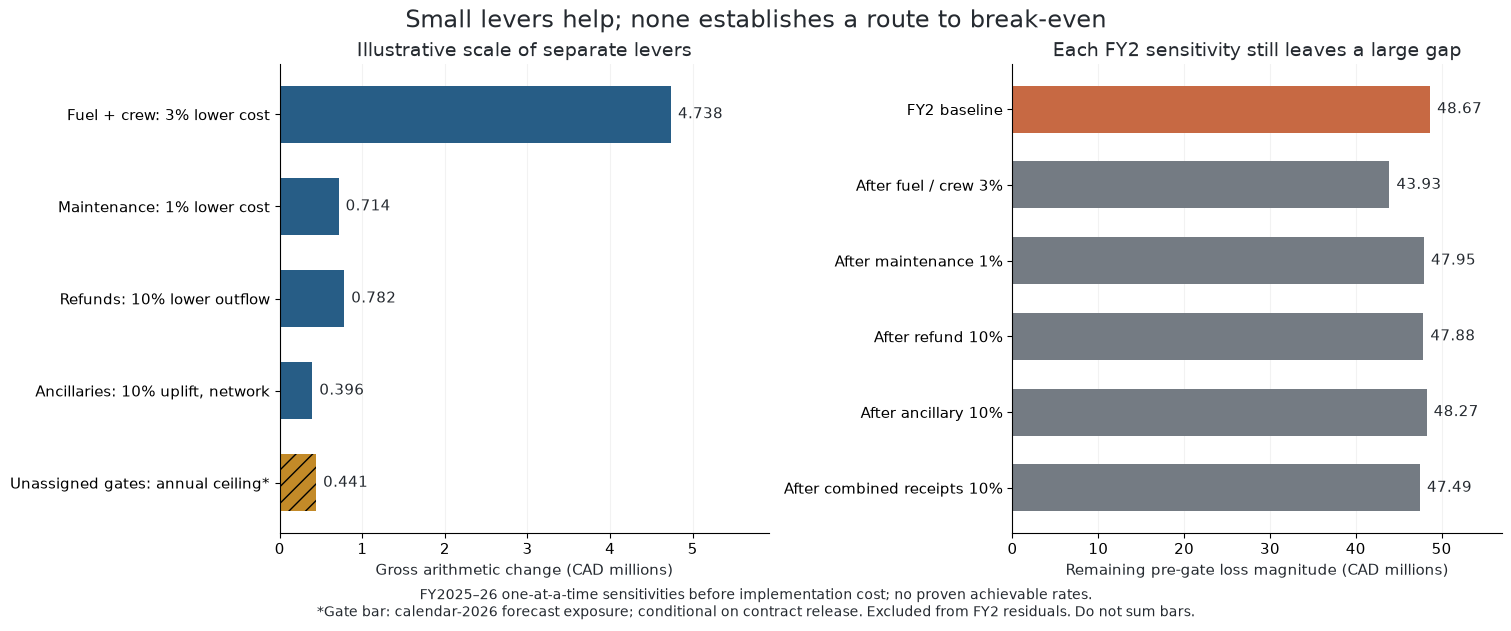

In [5]:
plot_ids = ['FC3', 'M1', 'R10', 'A10', 'G100']
labels = [
    'Fuel + crew: 3% lower cost',
    'Maintenance: 1% lower cost',
    'Refunds: 10% lower outflow',
    'Ancillaries: 10% uplift, network',
    'Unassigned gates: annual ceiling*',
]
plot_scenarios = by_id.loc[plot_ids]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), layout='constrained')
values = plot_scenarios.gross_improvement_cad / 1e6
bars = axes[0].barh(labels, values, color=[COLORS['blue']] * 4 + [COLORS['gold']], height=.62)
bars[-1].set_hatch('//')
axes[0].invert_yaxis()
axes[0].bar_label(bars, labels=[f'{value:.3f}' for value in values], padding=5)
axes[0].set_xlim(0, values.max() * 1.25)
axes[0].set_xlabel('Gross arithmetic change (CAD millions)')
axes[0].set_title('Illustrative scale of separate levers', fontsize=14)

residual_ids = ['FC3', 'M1', 'R10', 'A10', 'AR10']
residual_values = [loss_cents / 100_000_000] + (by_id.loc[residual_ids, 'remaining_pre_gate_loss_cad'] / 1e6).tolist()
residual_labels = ['FY2 baseline', 'After fuel / crew 3%', 'After maintenance 1%', 'After refund 10%', 'After ancillary 10%', 'After combined receipts 10%']
bars = axes[1].barh(residual_labels, residual_values, color=[COLORS['orange']] + [COLORS['grey']] * 5, height=.62)
axes[1].invert_yaxis()
axes[1].bar_label(bars, labels=[f'{value:.2f}' for value in residual_values], padding=5)
axes[1].set_xlim(0, 57)
axes[1].set_xlabel('Remaining pre-gate loss magnitude (CAD millions)')
axes[1].set_title('Each FY2 sensitivity still leaves a large gap', fontsize=14)

for ax in axes:
    ax.grid(axis='x', alpha=.16)
    ax.set_axisbelow(True)
fig.suptitle('Small levers help; none establishes a route to break-even', fontsize=17)
fig.supxlabel(
    'FY2025–26 one-at-a-time sensitivities before implementation cost; no proven achievable rates.\n'
    '*Gate bar: calendar-2026 forecast exposure; conditional on contract release. Excluded from FY2 residuals. Do not sum bars.',
    fontsize=10,
)
save_figure(fig, '06_lever_sensitivities')
plt.show()

### Priority 6 · Make long-term network, Rewards and investment decisions measurable

**Days 0–30, in parallel with priorities 1–5:** the CFO and data team should create a booking-to-flown-leg bridge, recover lease contracts and retain the date exclusion ledger. Join disruption reasons, flown passengers/seats, aircraft cycles, crew hours and fuel volumes at a defined grain. This is an enabling task, not a measured savings claim. The current CAD48.67m pre-gate gap and CAD10.02m estimated gate layer justify fixing the measurement before irreversible commitments.

**Months 3–12:** verify feeder itineraries and measure total network contribution before regional frequency changes. The inferred connection-compatible class supplies **CAD13,082,465.88 (6.90%) of FY2 net receipts**, but routes/timestamps cannot prove actual connecting travel or incremental profit. Protect minimum viable links and connection windows through consultation; seek partnership or shared service options only when cost, reliability and accessibility are demonstrated. No regional closure benefit is quantified.

Audit Rewards redemption liability, point unit values, servicing cost and repeat-purchase behavior before changing benefits. FY2 **Points + Cash recorded ticket receipts of CAD19,739,857.11 are revenue exposure, never Rewards cost**. Use a properly measured pilot to compare incremental retained contribution with benefit and administration costs. Honor accrued benefits and clear customer terms. Avoid sweeping cuts based on membership averages; employee training and community access should be part of any redesigned offer.

**Months 6–18:** commit to sustained capacity/fleet changes, lease renewals or Rewards investments only when the above evidence supports net-positive contribution after transition and fixed commitments. Fleet acquisition, hedging and blanket fare/loyalty cuts cannot be financially justified from the supplied fields. A matched-period financial plan and cash/contract review are required to determine whether a feasible route to sustainable profit exists; this case data alone cannot establish financing needs or a break-even date.

## Prioritized action register

The numerical amounts below are either **observed exposure**, **forecast exposure** or **mechanical sensitivity**; the evidence type is explicit. Lower-ranked work can run in parallel where it does not divert scarce operations and analytical capacity from the first two priorities. Timing is relative to management approval; no calendar-2026 rate is assumed to be a current contract quote.

In [6]:
actions = pd.DataFrame([
    {
        'priority': 1,
        'action': 'Review four corridors and pilot safe fuel / crew productivity',
        'timing': '0–30 days diagnosis; 30–90 day pilot; 3–12 month schedule decisions',
        'owner': 'COO + Network Planning + CFO',
        'financial_justification': f'{top_eight_decline_cents / decline_cents * 100:.2f}% of decline in eight directions; {money(fuel_crew_cents)} FY2 fuel / crew base',
        'sizing': f'FC3: {money(by_id.loc["FC3", "gross_improvement_cents"])} gross arithmetic headroom at 3%; no closure savings identified',
        'evidence_type': 'Observed concentration; illustrative expense sensitivity',
        'release_condition': 'Matched itinerary contribution, avoidable costs, safety and community-connection feasibility demonstrated',
    },
    {
        'priority': 2,
        'action': 'Audit maintenance purchasing and planning',
        'timing': '0–60 day audit; 3–12 month verified rollout',
        'owner': 'Engineering + Procurement + CFO',
        'financial_justification': f'{money(maintenance_cents)} FY2 cost; {money(int(cost_volume.loc["Maintenance", "growth_cents"]))} increase',
        'sizing': f'M1: {money(by_id.loc["M1", "gross_improvement_cents"])} at 1% before costs; no necessary work deferred',
        'evidence_type': 'Observed expense; illustrative expense sensitivity',
        'release_condition': 'Invoice / aircraft-cycle evidence, net benefit and unchanged required work, safety and reliability',
    },
    {
        'priority': 3,
        'action': 'Prevent disruptions; preserve eligible refunds',
        'timing': '0–30 day reason linkage; 30–90 day pilot; 3–12 month resilience plan',
        'owner': 'Operations Control + Customer Care',
        'financial_justification': f'{money(refund_cents)} FY2 outflow; {money(-int(bridge.loc[bridge.driver.eq("Refunds"), "change_in_proxy_cents"].iloc[0]))} increase',
        'sizing': f'R10: {money(by_id.loc["R10", "gross_improvement_cents"])} retained receipts at 10%; prevention costs unknown',
        'evidence_type': 'Observed outflow; illustrative receipt sensitivity',
        'release_condition': 'Preventable causes verified; net benefit after recovery cost; refund promise and service access preserved',
    },
    {
        'priority': 4,
        'action': 'Recover gate contracts; review Halifax A3 and Ottawa A2',
        'timing': '0–30 day contract recovery; 30–90 day feasibility; next contractual opportunity',
        'owner': 'Airport Stations + Property + CFO',
        'financial_justification': f'{money(unassigned_forecast_cents)} forecast annual unassigned exposure; {money(int(gate_forecast.forecast_2026_cents.sum()))} portfolio budget',
        'sizing': 'G100 is a conditional calendar-2026 annual ceiling, not promised savings; net benefit subtracts penalties / replacement cost',
        'evidence_type': 'Forecast exposure; no release or physical inactivity proven',
        'release_condition': 'Occupancy, contingency, accessibility, staffing and contractual sharing / exit rights confirmed',
    },
    {
        'priority': 5,
        'action': 'Test opt-in direct-channel ancillaries',
        'timing': '30–90 day controlled test; 3–12 month conditional scaling',
        'owner': 'Commercial + Digital + Customer Care',
        'financial_justification': f'{direct_net_cents / int(new.net_revenue_cents) * 100:.2f}% of net receipts direct; {money(direct_ancillary_cents)} direct ancillary base',
        'sizing': f'D10: {money(by_id.loc["D10", "gross_improvement_cents"])} at 10%; network A10 is a separate broader scenario',
        'evidence_type': 'Observed channel / ancillary bases; illustrative receipts',
        'release_condition': 'Incremental contribution after servicing / acquisition / technology cost, with conversion and complaint guardrails',
    },
    {
        'priority': 6,
        'action': 'Build matched economics; validate connectivity and Rewards before redesign',
        'timing': 'Data foundation begins day 0; 3–12 month pilots; 6–18 month capital / network decisions',
        'owner': 'CFO + Data + Network Planning + Loyalty',
        'financial_justification': f'{money(loss_cents)} pre-gate gap; {money(int(connection_latest.net_cents))} inferred connecting receipts; {money(int(points_latest.ticket_receipts_cents))} Points + Cash receipts',
        'sizing': 'No dollar saving or Rewards cost identified; approve investment only from validated incremental contribution',
        'evidence_type': 'Observed receipts and loss exposure; economics / achievable gain unknown',
        'release_condition': 'Flown-leg linkage, redemption liability and service cost; community alternatives; employee and customer transition plan',
    },
])
save_table(actions, '06_prioritized_actions')
display(actions[['priority', 'action', 'financial_justification', 'sizing']].style.hide(axis='index'))

priority,action,financial_justification,sizing
1,Review four corridors and pilot safe fuel / crew productivity,"71.16% of decline in eight directions; CAD 157,949,480.57 FY2 fuel / crew base","FC3: CAD 4,738,484.42 gross arithmetic headroom at 3%; no closure savings identified"
2,Audit maintenance purchasing and planning,"CAD 71,387,479.95 FY2 cost; CAD 13,003,356.24 increase","M1: CAD 713,874.80 at 1% before costs; no necessary work deferred"
3,Prevent disruptions; preserve eligible refunds,"CAD 7,821,083.19 FY2 outflow; CAD 1,142,771.50 increase","R10: CAD 782,108.32 retained receipts at 10%; prevention costs unknown"
4,Recover gate contracts; review Halifax A3 and Ottawa A2,"CAD 441,444.87 forecast annual unassigned exposure; CAD 10,095,844.04 portfolio budget","G100 is a conditional calendar-2026 annual ceiling, not promised savings; net benefit subtracts penalties / replacement cost"
5,Test opt-in direct-channel ancillaries,"62.07% of net receipts direct; CAD 2,458,562.69 direct ancillary base","D10: CAD 245,856.27 at 10%; network A10 is a separate broader scenario"
6,Build matched economics; validate connectivity and Rewards before redesign,"CAD 48,666,104.45 pre-gate gap; CAD 13,082,465.88 inferred connecting receipts; CAD 19,739,857.11 Points + Cash receipts",No dollar saving or Rewards cost identified; approve investment only from validated incremental contribution


## Implementation, feasibility and stakeholder effects

Run reversible tests first and stage any long-term commitment behind an evidence gate. Suggested monitoring below is a **proposed management process**, not a historical KPI result or a forecast. Baselines for on-time performance, complaints, fatigue and community journey time must be collected; the supplied files cannot supply them. Owners should agree acceptable service and workforce thresholds before launching each test.

The main tradeoff is fewer loss-exposed flights versus ticket and feeder demand, employee work and community access. Buying resilience may increase costs while reducing disruption; lease release may remove operational flexibility; additional ancillaries may displace fares or harm conversion. Preserve safety and required maintenance, legitimate refunds, transparent optional fees, appropriate crew rest and viable community connections as release conditions. Consult communities and employees before permanent changes; prefer retiming, partnerships, training and redeployment where feasible, without claiming these alternatives are proven cheaper.

In [7]:
roadmap = pd.DataFrame([
    {
        'stage': '1 · Establish evidence and constrain new exposure',
        'timing': 'Days 0–30',
        'actions': 'Hold discretionary net schedule growth; reconcile four corridor itineraries; recover leases; link disruptions; start maintenance invoice audit',
        'owner': 'CFO / COO, with Engineering and Stations',
        'evidence_gate': 'Booking-to-flown-leg reconciliation; fuel quantity / rate and crew hours / rate; invoice validity; contract terms; refund reason coverage',
        'financial_test': 'Reconcile each action to one base and one attributable benefit; all proposed spend has an owner and explicit cost',
        'service_people_test': 'Safety / maintenance / fatigue constraints retained; baseline complaints, connection success and community access; workforce consultation starts',
    },
    {
        'stage': '2 · Run bounded pilots and negotiate options',
        'timing': 'Days 30–90',
        'actions': 'Pilot retiming / productivity where feasible; test maintenance procurement; prevent identified disruptions; negotiate gate options; opt-in ancillary test',
        'owner': 'COO / Engineering / Commercial / Property',
        'evidence_gate': 'Comparable seasonal flights and control bookings; gate peak / contingency capacity; verified disruption cause; fully costed offer',
        'financial_test': 'Benefit net of displaced ticket / feeder contribution, implementation, servicing and transition costs; no overlapping benefit counted twice',
        'service_people_test': 'Stop if safety, required work, rest or customer promise compromised; review refunds paid, complaints, reliability, staff workload and community journey options',
    },
    {
        'stage': '3 · Scale verified improvements, protect viable links',
        'timing': 'Months 3–12; lease change only when contract permits',
        'actions': 'Scale positive-net-benefit pilots; adjust frequency / fleet fit after network review; redeploy staff; validate Rewards economics; update contract-based gate budget',
        'owner': 'Executive team with Network Planning / HR / Loyalty',
        'evidence_gate': 'Actual attributable benefit persists across season / aircraft mix; contracts enforceable; community and employee transitions agreed',
        'financial_test': 'Matched network contribution improves after fixed commitments; Rewards retained contribution exceeds redemption / service costs',
        'service_people_test': 'Maintain workable regional links and accessibility; honor accrued benefits; provide notice, retraining and redeployment; monitor local service impact',
    },
    {
        'stage': '4 · Decide long-term capital and network plan',
        'timing': 'Months 6–18',
        'actions': 'Approve durable network / fleet commitments and Rewards design only from validated business cases; assess cash and financing separately',
        'owner': 'Board / CFO / COO',
        'evidence_gate': 'Matched financial plan, cash / contract constraints, seasonality and downside cases; independently reviewed capital economics',
        'financial_test': 'Credible path to sustainable profit with cash and transition costs; no break-even date assumed from these sensitivities',
        'service_people_test': 'Board review of safety, customer fairness, employee transition and community connectivity alongside financial return',
    },
])
save_table(roadmap, '06_implementation_roadmap')
display(roadmap[['stage', 'timing', 'evidence_gate', 'financial_test']].style.hide(axis='index'))

stakeholders = pd.DataFrame([
    ['Customers', 'Fewer avoidable disruptions; clearer optional purchases; preserve full eligible refunds and accrued Rewards benefits', 'Consolidation may reduce departure choice; ancillary tests can harm conversion or affordability', 'Track rebooking / connection success, complaints, total price and timely eligible refund payment'],
    ['Employees', 'Better rostering, planned maintenance, training and redeployment can improve predictability', 'Schedule / gate consolidation may reduce hours or increase station workload; pilots add training burden', 'Consult before permanent changes; monitor rest, overtime, safety reports, workload and redeployment outcomes'],
    ['Communities', 'Protect viable regional / northern links and useful hub connection windows; retain accessible booking support', 'Frequency changes may lengthen journeys or weaken access; connectivity receipts do not establish subsidy need', 'Consult affected communities; measure journey alternatives and connection availability before changing essential access'],
])
stakeholders.columns = ['stakeholder', 'intended_effect', 'risk_or_tradeoff', 'proposed_monitoring_and_response']
save_table(stakeholders, '06_stakeholder_tradeoffs')
display(stakeholders.style.hide(axis='index'))

stage,timing,evidence_gate,financial_test
1 · Establish evidence and constrain new exposure,Days 0–30,Booking-to-flown-leg reconciliation; fuel quantity / rate and crew hours / rate; invoice validity; contract terms; refund reason coverage,Reconcile each action to one base and one attributable benefit; all proposed spend has an owner and explicit cost
2 · Run bounded pilots and negotiate options,Days 30–90,Comparable seasonal flights and control bookings; gate peak / contingency capacity; verified disruption cause; fully costed offer,"Benefit net of displaced ticket / feeder contribution, implementation, servicing and transition costs; no overlapping benefit counted twice"
"3 · Scale verified improvements, protect viable links",Months 3–12; lease change only when contract permits,Actual attributable benefit persists across season / aircraft mix; contracts enforceable; community and employee transitions agreed,Matched network contribution improves after fixed commitments; Rewards retained contribution exceeds redemption / service costs
4 · Decide long-term capital and network plan,Months 6–18,"Matched financial plan, cash / contract constraints, seasonality and downside cases; independently reviewed capital economics",Credible path to sustainable profit with cash and transition costs; no break-even date assumed from these sensitivities


stakeholder,intended_effect,risk_or_tradeoff,proposed_monitoring_and_response
Customers,Fewer avoidable disruptions; clearer optional purchases; preserve full eligible refunds and accrued Rewards benefits,Consolidation may reduce departure choice; ancillary tests can harm conversion or affordability,"Track rebooking / connection success, complaints, total price and timely eligible refund payment"
Employees,"Better rostering, planned maintenance, training and redeployment can improve predictability",Schedule / gate consolidation may reduce hours or increase station workload; pilots add training burden,"Consult before permanent changes; monitor rest, overtime, safety reports, workload and redeployment outcomes"
Communities,Protect viable regional / northern links and useful hub connection windows; retain accessible booking support,Frequency changes may lengthen journeys or weaken access; connectivity receipts do not establish subsidy need,Consult affected communities; measure journey alternatives and connection availability before changing essential access


## Validation and explicit limits

Check consequential scenario arithmetic independently with **standard-library `csv`, `Decimal` and exact `Fraction` arithmetic** against the selected input files, rather than calling the same calculation helper twice. Validate full precision before display rounding. Source notebook execution checks establish saved upstream state; they do not independently rerun Questions 1–5.

No field identifies flown-leg ticket revenue, seat capacity, true load factor, fuel quantity/rate, crew hours/rate, aircraft cycles, refund reason, Rewards cost, gate occupancy or current termination rights. Those gaps limit causality, feasibility, timing and dollar commitments. The gates' “unassigned” label does not prove physical nonuse. Connecting bookings are inferred; membership/payment receipts are overlapping partitions and cannot be added into a cost estimate.

The financial tests below validate **arithmetic and provenance**, not whether NorthByte can attain the illustrative rates. There is no summed program savings estimate. The conditional FY2 after-gate proxy is distinct from the pre-gate comparison, and forecast calendar-2026 gate exposure is kept out of FY2 residual scenarios.

In [8]:
# Independent arithmetic: read CSV strings separately and use rational rounding.
def read_csv_rows(stem):
    with (TABLES / f'{stem}.csv').open(newline='') as handle:
        return list(csv.DictReader(handle))


def round_positive_fraction(value):
    # Exact half-up rounding for nonnegative fractions; independent of rate_cents.
    return (2 * value.numerator + value.denominator) // (2 * value.denominator)


raw_cost_rows = read_csv_rows('03_cost_volume_and_average')
raw_receipt_row = next(row for row in read_csv_rows('04_revenue_bridge') if row['fiscal_year'] == FY_ORDER[1])
raw_direct_rows = [row for row in read_csv_rows('04_booking_channel') if row['fiscal_year'] == FY_ORDER[1] and row['booking_channel'] in {'Direct Web', 'Mobile App'}]
raw_gate_rows = [row for row in read_csv_rows('05_gate_change_forecast') if row['assigned_route_count'] == '0']
independent_bases = {
    'FC1': sum(int(row['fy26_cost_cents']) for row in raw_cost_rows if row['cost_type'] in {'Fuel', 'Crew'}),
    'M1': next(int(row['fy26_cost_cents']) for row in raw_cost_rows if row['cost_type'] == 'Maintenance'),
    'R10': int(raw_receipt_row['refund_cents']),
    'A10': int(raw_receipt_row['ancillary_cents']),
    'D10': sum(int(row['ancillary_cents']) for row in raw_direct_rows),
    'G100': sum(int(row['forecast_2026_cents']) for row in raw_gate_rows),
}
independent_bases['FC3'] = independent_bases['FC1']
independent_bases['FC5'] = independent_bases['FC1']
independent_bases['AR10'] = independent_bases['A10'] + independent_bases['R10']

raw_annual = next(row for row in read_csv_rows('03_annual_exact_totals') if row['fiscal_year'] == FY_ORDER[1])
independent_loss = -int(raw_annual['contribution_proxy_cents'])
for row in scenarios.itertuples(index=False):
    expected = round_positive_fraction(Fraction(independent_bases[row.scenario_id]) * Fraction(str(row.rate)))
    check(row.scenario_id + ' independent base', int(row.base_cents) == independent_bases[row.scenario_id], 'Read from CSV strings')
    check(row.scenario_id + ' independent scenario arithmetic', expected == int(row.gross_improvement_cents), expected)
    if row.period == 'FY2025-26':
        check(row.scenario_id + ' residual gap', int(row.remaining_pre_gate_loss_cents) == independent_loss - expected, 'Same FY2 pre-gate baseline')
        check(row.scenario_id + ' still loss-making', int(row.remaining_pre_gate_loss_cents) > 0, 'No break-even claim')

q4_combined = Decimal(str(receipt_sensitivities.loc[receipt_sensitivities.scenario.eq('Combined receipt sensitivity'), 'incremental_receipts_CAD'].iloc[0]))
check('Combined receipt sensitivity matches Q4', as_cents(q4_combined) == int(by_id.loc['AR10', 'gross_improvement_cents']), 'Rounded to cents')
check('Direct subset below network ancillary', 0 < direct_ancillary_cents < ancillary_cents, direct_ancillary_cents)
check('Gate annual ceiling excluded from FY2 residual', pd.isna(by_id.loc['G100', 'remaining_pre_gate_loss_cad']), 'Calendar versus fiscal periods kept separate')
check('Conditional after-gate proxy exact', after_gate_loss_cents == 5_868_923_381, 'Includes estimated gate bill once')
check('Action priorities complete and ordered', actions.priority.tolist() == list(range(1, 7)), '6 priorities with timing, owner, finance and release conditions')
check('Stakeholder groups complete', set(stakeholders.stakeholder) == {'Customers', 'Employees', 'Communities'}, 'Explicit effects, risks and monitoring')

validation = pd.DataFrame(checks)
save_table(validation, '06_validation')
print(f'{len(validation)} input, reconciliation, scope, scenario and coverage checks passed.')
print('Scenario arithmetic is verified; achievable savings, causal effects and timing remain unestimated.')

66 input, reconciliation, scope, scenario and coverage checks passed.
Scenario arithmetic is verified; achievable savings, causal effects and timing remain unestimated.


## Answer to Question 6

**NorthByte should prioritize flight economics, then reliability and smaller commercial / fixed-overhead actions.** The order is justified by the measured exposure, not a forecast of savings:

1. **Immediately review the four major problem corridors and fuel/crew productivity.** Eight directions account for **71.2% of the CAD36.10m deterioration**; FY2 fuel and crew cost **CAD157.95m**. Start with matched revenue, avoidable costs and safe schedule/roster pilots. A purely illustrative 3% reduction changes the proxy by **CAD4,738,484.42**, leaving **CAD43,927,620.03 negative** before project costs. Permanent cuts require feeder-demand and community-service evidence; recorded route losses are not closure savings.
2. **Audit maintenance purchasing and planning in the first 60 days.** Maintenance rose **CAD13.00m** to **CAD71.39m**. A 1% sensitivity is **CAD713,874.80** before costs; required work, airworthiness and reliability cannot be cut to attain it. Scale only verified efficiencies over months 3–12.
3. **Reduce preventable disruptions over the first 90 days**, honoring the full refund promise. FY2 refund outflow is **CAD7.82m**, up **CAD1.14m**. A hypothetical 10% fall through fewer disruptions retains **CAD782,108.32**, before prevention costs. Customers gain more reliable trips; employees need adequate recovery resources and safe workloads.
4. **Recover missing gate contracts immediately and review Halifax A3 / Ottawa A2 at the next contractual opportunity.** Plan around **CAD10.096m** for forecast calendar-2026 leases pending contracts. The two unassigned gates carry **CAD441,444.87** of annual forecast exposure, a conditional ceiling requiring feasible exit/sharing without replacement cost or service damage. It is not assured savings or a FY2 reduction.
5. **Test transparent optional ancillaries in direct channels over days 30–90.** Direct Web / Mobile App supply **62.07%** of net receipts. A 10% uplift on their actual CAD2,458,562.69 ancillary base is CAD245,856.27 before costs; the broader network-wide sensitivity is **CAD395,896.38** before servicing, technology and cannibalization costs. Scale only incremental contribution with acceptable conversion and complaints. Preserve fair fees and valid refunds.
6. **Start the data foundation now; use months 3–18 for measured network and Rewards redesign.** Match bookings to flown legs, validate inferred connections and obtain Rewards liabilities/service costs before changing benefits or regional links. **CAD13.08m of inferred connecting receipts and CAD19.74m of Points + Cash ticket receipts describe revenue exposure; neither identifies incremental profit or Rewards cost.** Protect accrued benefits, workable regional/northern connections and accessible booking. Consult communities and employees, and favor training and redeployment before permanent schedule or station changes.

**Implementation and tradeoffs:** CFO/COO ownership begins at day 0, engineering and customer teams run bounded pilots by day 90, and the executive team scales only net-positive, safe improvements over months 3–12. Long-term capital and network commitments follow validated contribution, cash/contract economics and employee/community transition plans over months 6–18. Fewer departures or gates may reduce choice and operating flexibility; additional resilience may cost more; optional offers may reduce conversion. Monitor these alongside safety, crew rest, customer complaints, timely refunds and community journey options.

**Financial limit:** the combined 10% network ancillary/refund sensitivity is just **CAD1,178,004.70 (2.42%)** of the **CAD48,666,104.45 pre-gate loss proxy**, before implementation costs. The conditional proxy loss after estimated gates is **CAD58,689,233.81**. Do not sum overlapping cost, reliability, route, direct-channel and network scenarios into a savings promise. This evidence supports a staged turnaround investigation and pilots; it does not establish an achievable savings total, a break-even date or a justified financing requirement.